#### data import

In [1]:
import pandas as pd
df=pd.read_csv("Employee_Attrition.csv")
df.head()

,Age,Attrition,BusinessTravel,Department,DistanceFromHome,Education,EnvironmentSatisfaction,Gender,JobInvolvement,JobRole,...,MaritalStatus,MonthlyIncome,OverTime,RelationshipSatisfaction,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion
0,41,Yes,Travel_Rarely,Sales,1,2,2,Female,3,Sales Executive,...,Single,5993,Yes,1,8,0,1,6,4,0
1,49,No,Travel_Frequently,Research & Development,8,1,3,Male,2,Research Scientist,...,Married,5130,No,4,10,3,3,10,7,1
2,37,Yes,Travel_Rarely,Research & Development,2,2,4,Male,2,Laboratory Technician,...,Single,2090,Yes,2,7,3,3,0,0,0
3,33,No,Travel_Frequently,Research & Development,3,4,4,Female,3,Research Scientist,...,Married,2909,Yes,3,8,3,3,8,7,3
4,27,No,Travel_Rarely,Research & Development,2,1,1,Male,3,Laboratory Technician,...,Married,3468,No,4,6,3,3,2,2,2


### data cheak

In [2]:
df.shape
df.info()
df.isnull().sum()
df["Attrition"].value_counts()



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 21 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   Department                1470 non-null   object
 4   DistanceFromHome          1470 non-null   int64 
 5   Education                 1470 non-null   int64 
 6   EnvironmentSatisfaction   1470 non-null   int64 
 7   Gender                    1470 non-null   object
 8   JobInvolvement            1470 non-null   int64 
 9   JobRole                   1470 non-null   object
 10  JobSatisfaction           1470 non-null   int64 
 11  MaritalStatus             1470 non-null   object
 12  MonthlyIncome             1470 non-null   int64 
 13  OverTime                  1470 non-null   object
 14  RelationshipSatisfaction

Attrition
No     1233
Yes     237
Name: count, dtype: int64

In [3]:

df["Attrition"].value_counts(normalize=True)*100

Attrition
No     83.877551
Yes    16.122449
Name: proportion, dtype: float64

### Report 

The dataset contains 1470 employees and 21 variables with no missing values. Out of 1470 employees, 237 (16.12%) left the company, while 1233 (83.88%) remained employed. The dataset consists of 14 numerical and 7 categorical variables.

# EDA

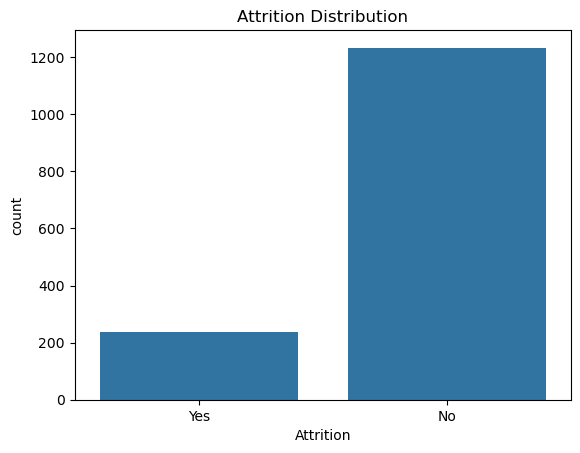

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(x="Attrition",data=df)
plt.title("Attrition Distribution")
plt.show()

In [5]:
## Crosstab + %

a=pd.crosstab(
    df["OverTime"],
    df["Attrition"],                       ## OverTime vs Attrition
    normalize="index"
)*100
print(a)

b=pd.crosstab(
    df["MaritalStatus"],                   ## MaritalStatus vs Attrition
    df["Attrition"],
    normalize="index"
)*100
print(b)

c=pd.crosstab(
    df["Department"],
    df["Attrition"],                       ## Department vs Attrition
    normalize="index"
)*100
print(c)

d=pd.crosstab(
    df["JobRole"],
    df["Attrition"],                       ##JobRole vs Attrition
    normalize="index"
)*100
print(d)

Attrition         No        Yes
OverTime                       
No         89.563567  10.436433
Yes        69.471154  30.528846
Attrition             No        Yes
MaritalStatus                      
Divorced       89.908257  10.091743
Married        87.518574  12.481426
Single         74.468085  25.531915
Attrition                      No        Yes
Department                                  
Human Resources         80.952381  19.047619
Research & Development  86.160250  13.839750
Sales                   79.372197  20.627803
Attrition                         No        Yes
JobRole                                        
Healthcare Representative  93.129771   6.870229
Human Resources            76.923077  23.076923
Laboratory Technician      76.061776  23.938224
Manager                    95.098039   4.901961
Manufacturing Director     93.103448   6.896552
Research Director          97.500000   2.500000
Research Scientist         83.904110  16.095890
Sales Executive            82.51533

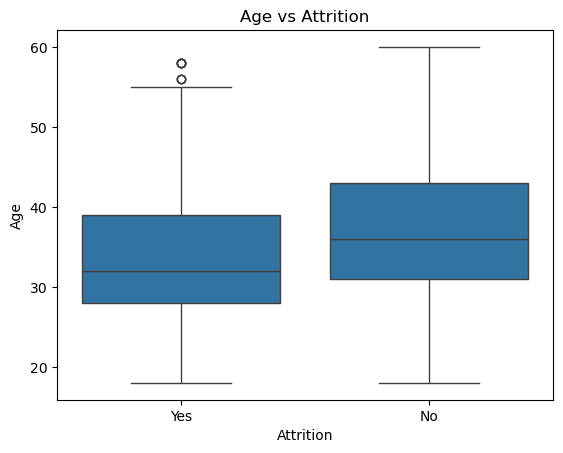

In [6]:
sns.boxplot(x="Attrition", y="Age", data=df)
plt.title("Age vs Attrition")
plt.show()

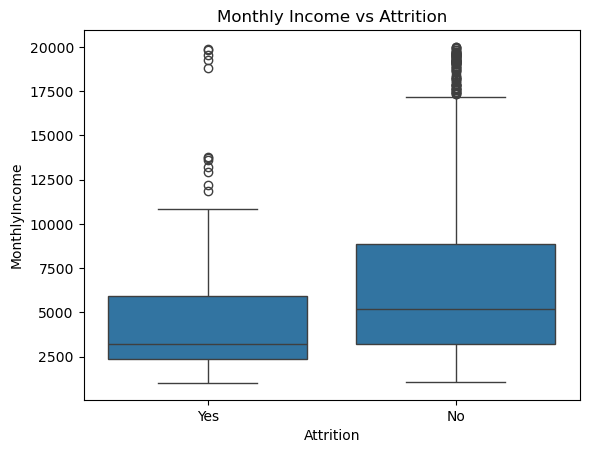

In [7]:
sns.boxplot(x="Attrition", y="MonthlyIncome", data=df)
plt.title("Monthly Income vs Attrition")
plt.show()

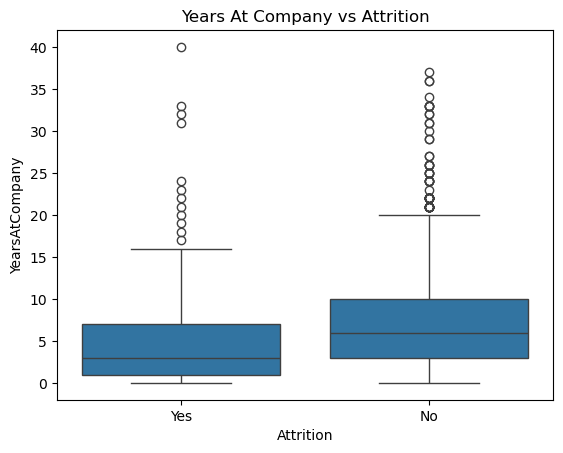

In [8]:
sns.boxplot(x="Attrition", y="YearsAtCompany", data=df)
plt.title("Years At Company vs Attrition")
plt.show()

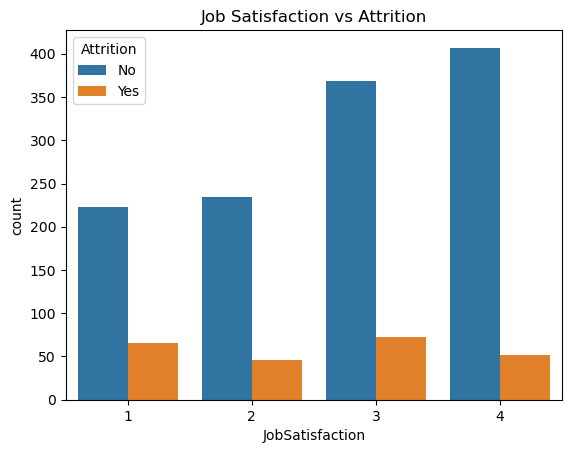

In [9]:
sns.countplot(x="JobSatisfaction", hue="Attrition", data=df)
plt.title("Job Satisfaction vs Attrition")
plt.show()

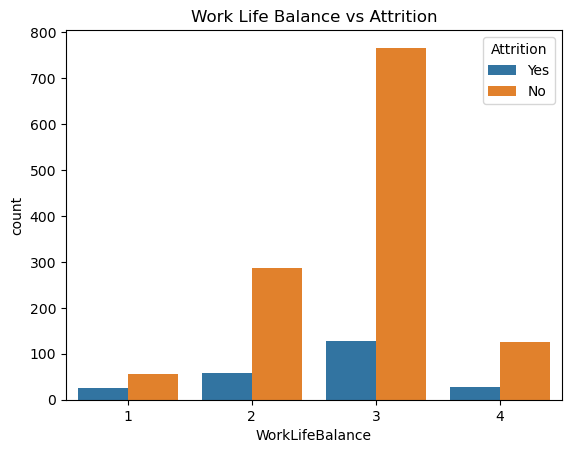

In [10]:
sns.countplot(x="WorkLifeBalance", hue="Attrition", data=df)
plt.title("Work Life Balance vs Attrition")
plt.show()

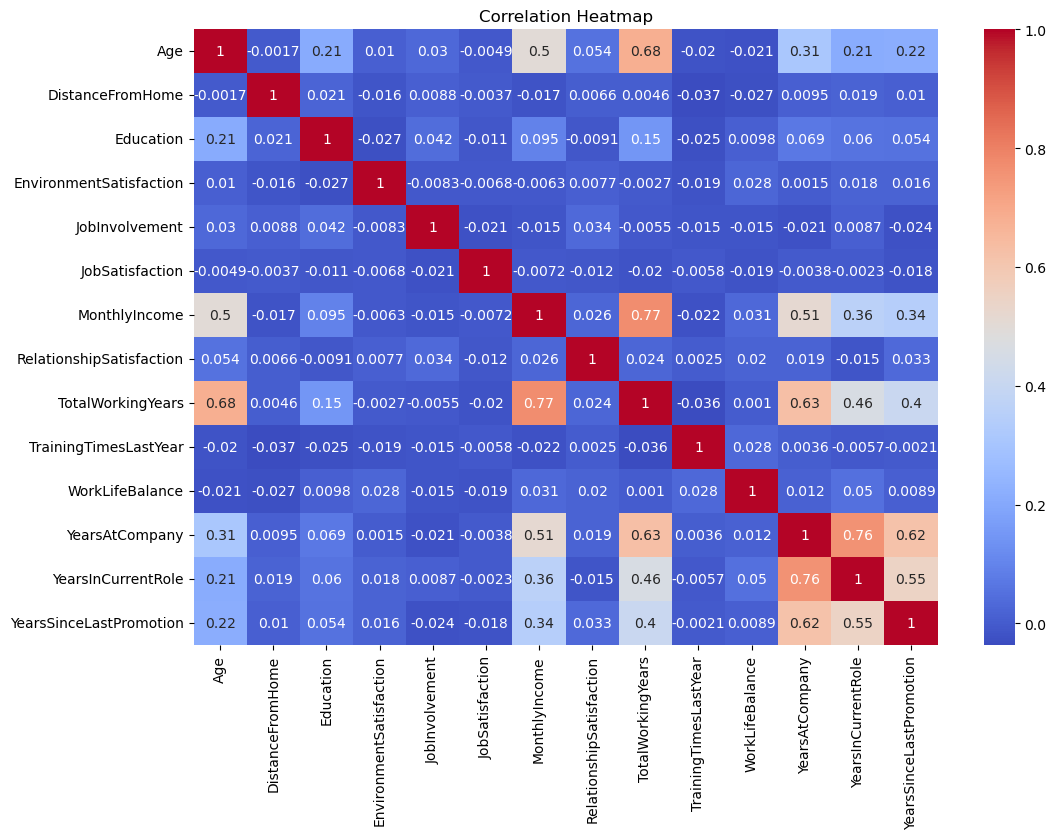

In [11]:
plt.figure(figsize=(12,8))

corr = df.select_dtypes(include='number').corr()

sns.heatmap(corr, annot=True, cmap='coolwarm')

plt.title("Correlation Heatmap")
plt.show()

### conclusion
The exploratory data analysis revealed several important factors associated with employee attrition. Employees working overtime exhibited a significantly higher attrition rate compared to those not working overtime. Employees who left the organization generally had lower monthly incomes and fewer years at the company. Job satisfaction and work-life balance also showed a noticeable relationship with attrition, suggesting that employee well-being plays an important role in retention.

The analysis indicates that compensation, overtime workload, job satisfaction, work-life balance, and employee tenure are key factors influencing employee attrition.

In [12]:
## Normality Check
from scipy.stats import shapiro

num_cols = ['Age','MonthlyIncome','YearsAtCompany','TotalWorkingYears']

for col in num_cols:
    stat, p = shapiro(df[col])

    print(f"\n{col}")
    print("P-value =", p)

    if p > 0.05:
        print("Normally Distributed")
    else:
        print("Not Normally Distributed")


Age
P-value = 2.036924313471409e-14
Not Normally Distributed

MonthlyIncome
P-value = 4.40239403650134e-37
Not Normally Distributed

YearsAtCompany
P-value = 3.668867045982291e-36
Not Normally Distributed

TotalWorkingYears
P-value = 5.63092214228768e-29
Not Normally Distributed


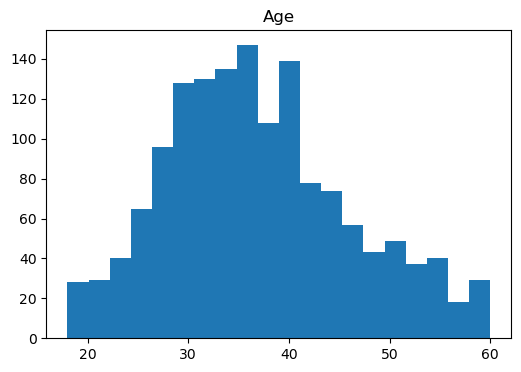

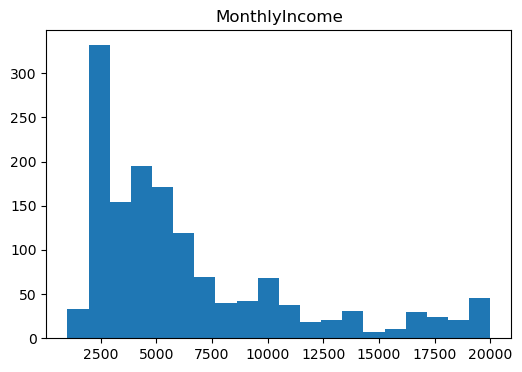

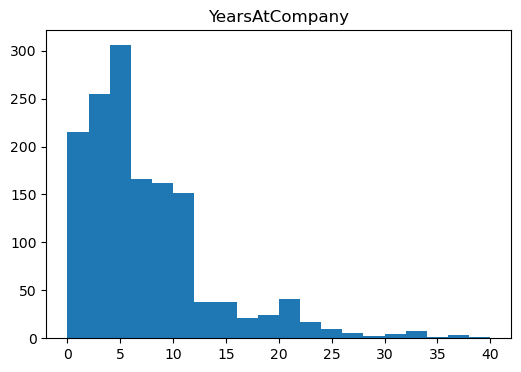

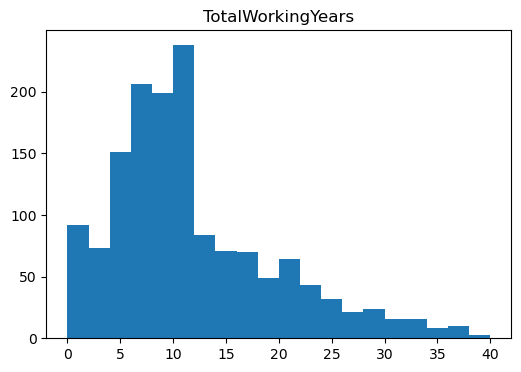

In [13]:
## Histogram
import matplotlib.pyplot as plt

for col in num_cols:
    plt.figure(figsize=(6,4))
    plt.hist(df[col], bins=20)
    plt.title(col)
    plt.show()

In [14]:
## Transformation

import numpy as np

df['Log_MonthlyIncome'] = np.log1p(df['MonthlyIncome'])
df['Log_TotalWorkingYears'] = np.log1p(df['TotalWorkingYears'])

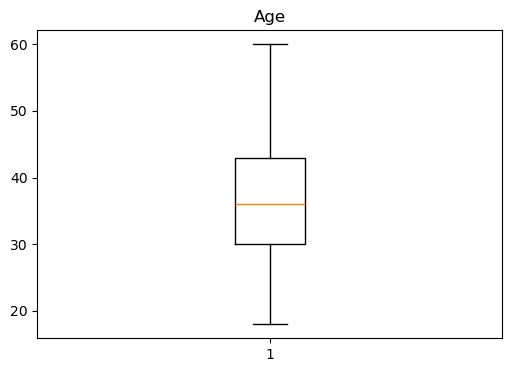

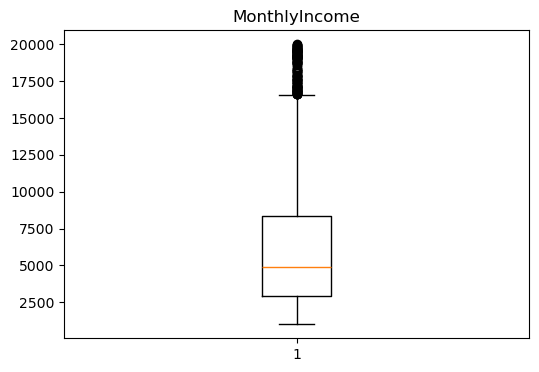

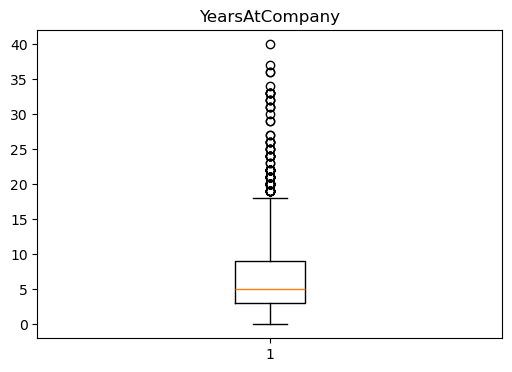

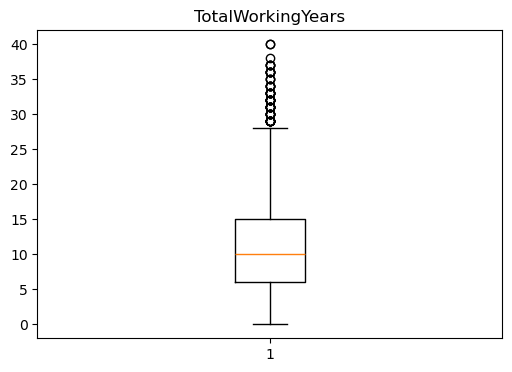

In [15]:
## Outlier Detection

for col in ['Age','MonthlyIncome','YearsAtCompany','TotalWorkingYears']:
    plt.figure(figsize=(6,4))
    plt.boxplot(df[col])
    plt.title(col)
    plt.show()

## Chi-Square Test

In [16]:

## OverTime vs Attrition
from scipy.stats import chi2_contingency

table = pd.crosstab(df["OverTime"], df["Attrition"])

chi2, p, dof, expected = chi2_contingency(table)

print("Chi-square:", chi2)
print("p-value:", p)

Chi-square: 87.56429365828768
p-value: 8.15842372153832e-21


In [17]:

##MaritalStatus vs Attrition
table = pd.crosstab(df["MaritalStatus"], df["Attrition"])

chi2, p, dof, expected = chi2_contingency(table)

print("Chi-square:", chi2)
print("p-value:", p)

Chi-square: 46.163676540848705
p-value: 9.45551106034083e-11


In [18]:

## Department vs Attrition
table = pd.crosstab(df["Department"], df["Attrition"])

chi2, p, dof, expected = chi2_contingency(table)

print("Chi-square:", chi2)
print("p-value:", p)

Chi-square: 10.79600732241067
p-value: 0.004525606574479633


In [19]:
## JobRole vs Attrition 
from scipy.stats import chi2_contingency

table = pd.crosstab(df["JobRole"], df["Attrition"])

chi2, p, dof, expected = chi2_contingency(table)

print("Chi-square =", chi2)
print("p-value =", p)

Chi-square = 86.19025367670434
p-value = 2.752481638050657e-15


## Independent t-Test

In [20]:
## MonthlyIncome vs Attrition
from scipy.stats import ttest_ind

yes = df[df["Attrition"]=="Yes"]["MonthlyIncome"]
no = df[df["Attrition"]=="No"]["MonthlyIncome"]

t_stat, p = ttest_ind(yes, no)

print("t-statistic:", t_stat)
print("p-value:", p)

t-statistic: -6.203935765608938
p-value: 7.147363985353811e-10


In [21]:
##Age vs Attrition
yes = df[df["Attrition"]=="Yes"]["Age"]
no = df[df["Attrition"]=="No"]["Age"]

t_stat, p = ttest_ind(yes, no)

print("t-statistic:", t_stat)
print("p-value:", p)

t-statistic: -6.178663835307217
p-value: 8.356308021103587e-10


In [22]:
## YearsAtCompany vs Attrition 
from scipy.stats import ttest_ind

yes = df[df["Attrition"]=="Yes"]["YearsAtCompany"]
no = df[df["Attrition"]=="No"]["YearsAtCompany"]

t_stat, p = ttest_ind(yes, no)

print("t-statistic =", t_stat)
print("p-value =", p)

t-statistic = -5.1963086670254235
p-value = 2.3188716103863036e-07


In [23]:
## Encoding
from sklearn.preprocessing import LabelEncoder

df_ml = df.copy()

le = LabelEncoder()

for col in df_ml.select_dtypes(include='object').columns:
    df_ml[col] = le.fit_transform(df_ml[col])

df_ml.head()

,Age,Attrition,BusinessTravel,Department,DistanceFromHome,Education,EnvironmentSatisfaction,Gender,JobInvolvement,JobRole,...,OverTime,RelationshipSatisfaction,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,Log_MonthlyIncome,Log_TotalWorkingYears
0,41,1,2,2,1,2,2,0,3,7,...,1,1,8,0,1,6,4,0,8.698514,2.197225
1,49,0,1,1,8,1,3,1,2,6,...,0,4,10,3,3,10,7,1,8.543056,2.397895
2,37,1,2,1,2,2,4,1,2,2,...,1,2,7,3,3,0,0,0,7.645398,2.079442
3,33,0,1,1,3,4,4,0,3,6,...,1,3,8,3,3,8,7,3,7.975908,2.197225
4,27,0,2,1,2,1,1,1,3,2,...,0,4,6,3,3,2,2,2,8.151622,1.945910


In [24]:
## VIF (Multicollinearity Check)

from statsmodels.stats.outliers_influence import variance_inflation_factor
import pandas as pd

# Log transformed variable remove
df_vif = df.drop(["Log_TotalWorkingYears","Log_MonthlyIncome"], axis=1)

# Target remove
X = df_vif.drop("Attrition", axis=1)

# Encoding
X = pd.get_dummies(X, drop_first=True)

# Numeric conversion
X = X.astype(float)

# VIF
vif = pd.DataFrame()
vif["Feature"] = X.columns
vif["VIF"] = [variance_inflation_factor(X.values, i)
              for i in range(X.shape[1])]

vif = vif.sort_values(by="VIF", ascending=False)

print(vif)

                              Feature        VIF
16  Department_Research & Development  43.207522
0                                 Age  33.535625
17                   Department_Sales  32.591048
6                       MonthlyIncome  23.318152
25            JobRole_Sales Executive  17.476206
10                    WorkLifeBalance  15.635680
4                      JobInvolvement  15.199193
8                   TotalWorkingYears  14.102850
2                           Education   9.445861
11                     YearsAtCompany   8.208530
15       BusinessTravel_Travel_Rarely   7.959873
7            RelationshipSatisfaction   7.372617
3             EnvironmentSatisfaction   7.141833
5                     JobSatisfaction   6.985748
12                 YearsInCurrentRole   6.021380
9               TrainingTimesLastYear   5.777680
26       JobRole_Sales Representative   5.364368
21                    JobRole_Manager   4.343512
24         JobRole_Research Scientist   3.886850
20      JobRole_Labo

In [25]:
## Train-Test Split
from sklearn.model_selection import train_test_split

X = df_ml.drop('Attrition', axis=1)
y = df_ml['Attrition']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print(X_train.shape)
print(X_test.shape)

(1176, 22)
(294, 22)


In [28]:
## StandardScaler 

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [29]:
## Logistic Regression
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(max_iter=1000)

lr.fit(X_train, y_train)

lr_pred = lr.predict(X_test)

In [30]:
## Logistic Regression Evaluation
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

print("Accuracy:")
print(accuracy_score(y_test, lr_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, lr_pred))

print("\nClassification Report:")
print(classification_report(y_test, lr_pred))

Accuracy:
0.8809523809523809

Confusion Matrix:
[[248   7]
 [ 28  11]]

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.97      0.93       255
           1       0.61      0.28      0.39        39

    accuracy                           0.88       294
   macro avg       0.75      0.63      0.66       294
weighted avg       0.86      0.88      0.86       294



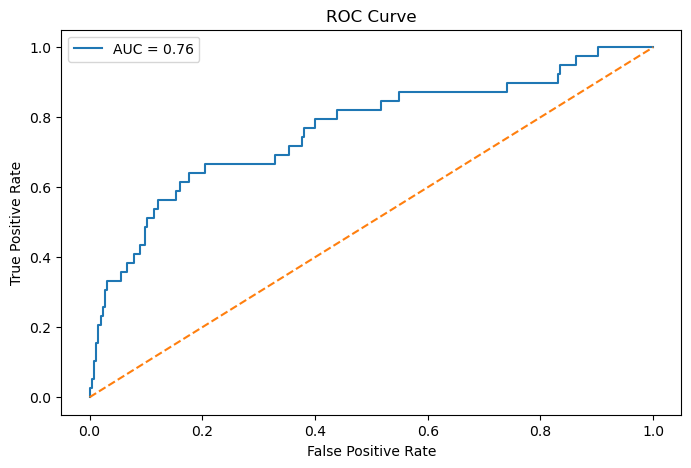

In [31]:
## ROC Curve for Logistic Regression 
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

y_prob = lr.predict_proba(X_test)[:,1]

fpr, tpr, thresholds = roc_curve(y_test, y_prob)

roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8,5))
plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.2f}")
plt.plot([0,1],[0,1],'--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

In [32]:
## Random Forest (Bagging)
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)

print("Random Forest Accuracy:")
print(accuracy_score(y_test, rf_pred))

Random Forest Accuracy:
0.8571428571428571


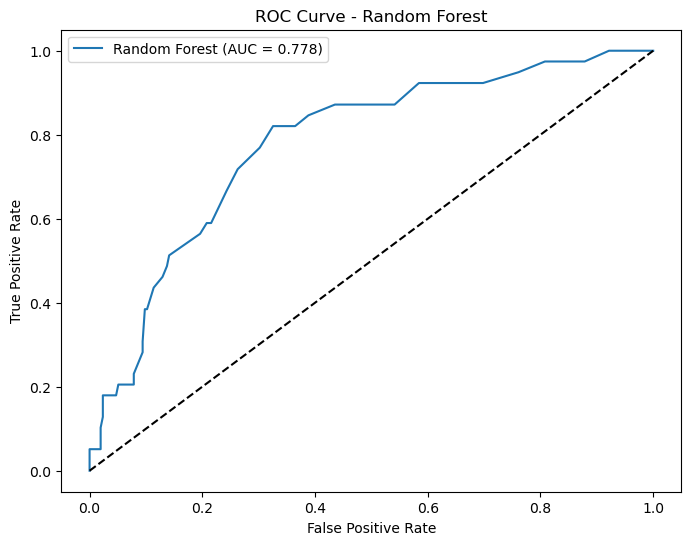

AUC Score: 0.7781297134238311


In [33]:
## ROC Curve for random forest
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Random Forest probability prediction
rf_probs = rf.predict_proba(X_test)[:, 1]

# ROC values
fpr, tpr, thresholds = roc_curve(y_test, rf_probs)

# AUC Score
auc_score = roc_auc_score(y_test, rf_probs)

# Plot
plt.figure(figsize=(8,6))
plt.plot(fpr, tpr,
         label=f'Random Forest (AUC = {auc_score:.3f})')

plt.plot([0,1], [0,1], 'k--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Random Forest")
plt.legend()
plt.show()

print("AUC Score:", auc_score)

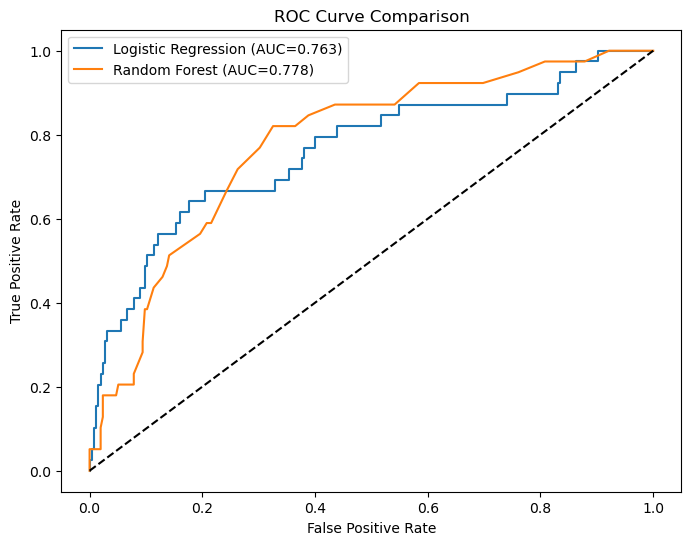

Logistic Regression AUC: 0.763097033685269
Random Forest AUC: 0.7781297134238311


In [34]:
## ROC Comparison b/w logistic and random forest
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Logistic Regression
lr_probs = lr.predict_proba(X_test)[:,1]
lr_fpr, lr_tpr, _ = roc_curve(y_test, lr_probs)
lr_auc = roc_auc_score(y_test, lr_probs)

# Random Forest
rf_probs = rf.predict_proba(X_test)[:,1]
rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_probs)
rf_auc = roc_auc_score(y_test, rf_probs)

plt.figure(figsize=(8,6))

plt.plot(lr_fpr, lr_tpr,
         label=f'Logistic Regression (AUC={lr_auc:.3f})')

plt.plot(rf_fpr, rf_tpr,
         label=f'Random Forest (AUC={rf_auc:.3f})')

plt.plot([0,1],[0,1],'k--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.show()

print("Logistic Regression AUC:", lr_auc)
print("Random Forest AUC:", rf_auc)

In [35]:
##Naive Bayes 

from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score

nb = GaussianNB()

nb.fit(X_train, y_train)

y_pred_nb = nb.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_nb))

Accuracy: 0.8605442176870748


In [36]:
## Gradient Boosting
from sklearn.ensemble import GradientBoostingClassifier

gb = GradientBoostingClassifier()

gb.fit(X_train, y_train)

gb_pred = gb.predict(X_test)

print("Gradient Boosting Accuracy:")
print(accuracy_score(y_test, gb_pred))

Gradient Boosting Accuracy:
0.8741496598639455


In [37]:
## AdaBoost
from sklearn.ensemble import AdaBoostClassifier

ab = AdaBoostClassifier()

ab.fit(X_train, y_train)

ab_pred = ab.predict(X_test)

print("AdaBoost Accuracy:")
print(accuracy_score(y_test, ab_pred))

AdaBoost Accuracy:
0.8707482993197279


In [38]:
## Model Comparison
print("Logistic Regression :", accuracy_score(y_test, lr_pred))
print("Random Forest       :", accuracy_score(y_test, rf_pred))
print("Naive Bayes         :", accuracy_score(y_test, y_pred_nb))
print("Gradient Boosting   :", accuracy_score(y_test, gb_pred))
print("AdaBoost            :", accuracy_score(y_test, ab_pred))

Logistic Regression : 0.8809523809523809
Random Forest       : 0.8571428571428571
Naive Bayes         : 0.8605442176870748
Gradient Boosting   : 0.8741496598639455
AdaBoost            : 0.8707482993197279


In [39]:
## Feature Importance
importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf.feature_importances_
})

importance = importance.sort_values(
    by='Importance',
    ascending=False
)

importance.head(10)

,Feature,Importance
11,MonthlyIncome,0.095726
20,Log_MonthlyIncome,0.093658
12,OverTime,0.075094
0,Age,0.073515
3,DistanceFromHome,0.066211
14,TotalWorkingYears,0.055731
17,YearsAtCompany,0.052438
21,Log_TotalWorkingYears,0.051704
10,MaritalStatus,0.040143
9,JobSatisfaction,0.039132


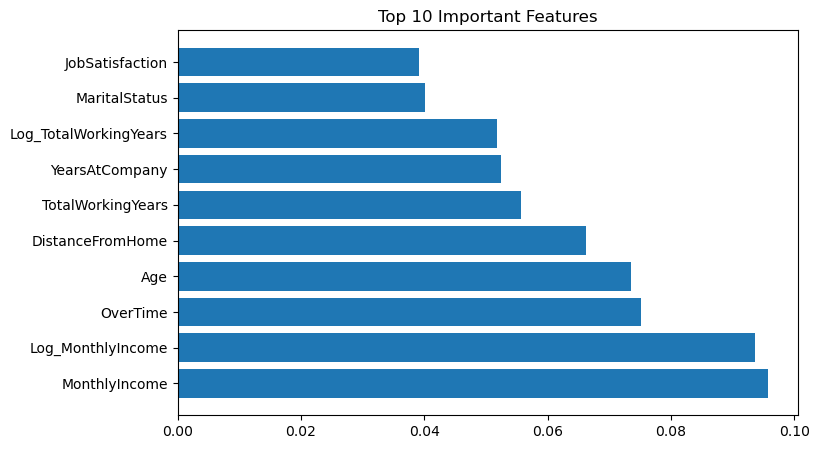

In [40]:
## Feature Importance Plot
top10 = importance.head(10)

plt.figure(figsize=(8,5))
plt.barh(top10['Feature'], top10['Importance'])
plt.title("Top 10 Important Features")
plt.show()

### Conclusion

Employee Attrition is significantly associated with factors such as
OverTime, Job Role, Department, Monthly Income, Age and Years At Company.

Machine Learning models were applied to predict employee attrition.
The model with the highest accuracy was selected as the best predictive model.

The results can help organizations identify employees who are at risk
of leaving and improve employee retention strategies.
